# Adjacency Matrix (ordered)

**Family:** Flow &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Flow:* Show the volume or intensity of movement between states, stages, or places.

## Design purpose

A network drawn as a grid: one row and one column per node, with each cell shaded by the strength of the link between them. The power is in the ordering. Reordered so that similar nodes sit together, clusters appear as dark blocks on the diagonal, and every link stays visible without the overlap of node-link diagrams.

## When to use

- Show dense networks (dozens to hundreds of nodes) where a node-link drawing becomes a hairball
- Reveal communities, bridges and outliers by reordering rows and columns
- Show weighted links precisely (overlap, exposure, correlation, message counts)

## Avoid when

- Readers need to trace paths through several hops (node-link diagrams show paths better)
- The network is small and sparse (a network graph is more intuitive)
- Rows are left in arbitrary (e.g. alphabetical) order, which hides all structure

## Alternatives

- Network graph (force-directed)
- Hierarchical edge bundling
- Clustered heatmap

## Design tips

- Order rows by hierarchical clustering or community detection, never alphabetically
- Use one-hue sequential color with white for "no link"
- Outline detected clusters and label them on the margin

## Example

Simulated portfolio overlap between 40 investment funds: the share of holdings two funds have in common. The funds come from four strategy groups, but their IDs are assigned at random.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

### Data

In [2]:
rng = np.random.default_rng(8)
groups = ["Growth", "Value", "Dividend", "Small cap"]
n = 40
group = rng.permutation(np.repeat(np.arange(4), n // 4))       # strategy of each fund (hidden in ID order)
base = np.where(group[:, None] == group[None, :], 0.45, 0.06)  # same strategy -> large overlap
overlap = np.clip(base + rng.normal(0, 0.07, (n, n)), 0, 1)
overlap = np.triu(overlap, 1)
overlap = overlap + overlap.T                                  # symmetric, zero diagonal
overlap[overlap < 0.08] = 0                                    # tiny overlaps -> no link
funds = [f"F{i:02d}" for i in range(n)]
A = pd.DataFrame(overlap, index=funds, columns=funds)
A.iloc[:6, :6].round(2)

,F00,F01,F02,F03,F04,F05
F00,0.00,0.00,0.44,0.00,0.00,0.17
F01,0.00,0.00,0.00,0.42,0.49,0.00
F02,0.44,0.00,0.00,0.20,0.00,0.00
F03,0.00,0.42,0.20,0.00,0.33,0.09
F04,0.00,0.49,0.00,0.33,0.00,0.13
F05,0.17,0.00,0.00,0.09,0.13,0.00


### Plot

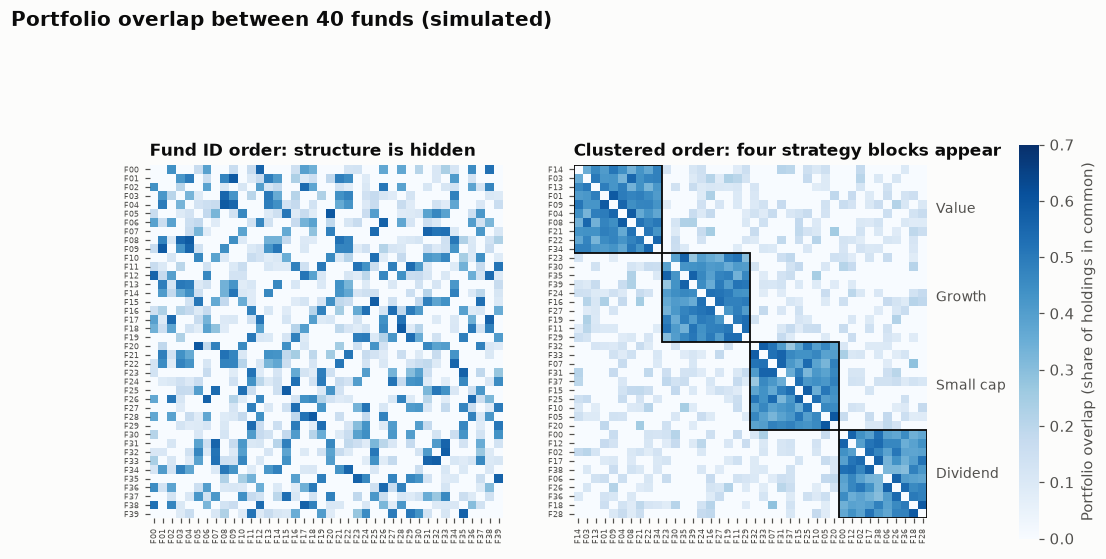

In [3]:
# Reorder by average-linkage clustering on distance = 1 - overlap
D = 1 - A.values
np.fill_diagonal(D, 0)
order = leaves_list(linkage(squareform(D), method="average"))
B = A.iloc[order, order]

fig, axes = plt.subplots(1, 2, figsize=(12, 6.2))
for ax, M, title in [(axes[0], A, "Fund ID order: structure is hidden"),
                     (axes[1], B, "Clustered order: four strategy blocks appear")]:
    im = ax.imshow(M.values, cmap=SEQ_CMAP, vmin=0, vmax=0.7, interpolation="nearest")
    ax.set_xticks(range(n), M.columns, rotation=90, fontsize=5.5)
    ax.set_yticks(range(n), M.index, fontsize=5.5)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, fontsize=11)
# Outline the clusters on the reordered matrix and name them on the margin
g_sorted = group[order]
start = 0
for i in range(1, n + 1):
    if i == n or g_sorted[i] != g_sorted[start]:
        axes[1].add_patch(plt.Rectangle((start - 0.5, start - 0.5), i - start, i - start,
                                        fill=False, edgecolor="#0b0b0b", linewidth=1.2))
        axes[1].text(n + 0.5, (start + i - 1) / 2, groups[g_sorted[start]], va="center",
                     fontsize=9, color="#52514e")
        start = i
cb = fig.colorbar(im, ax=axes, shrink=0.75, pad=0.09)
cb.set_label("Portfolio overlap (share of holdings in common)")
cb.outline.set_visible(False)
fig.suptitle("Portfolio overlap between 40 funds (simulated)", x=0.02, ha="left",
             fontsize=13, fontweight="bold")
plt.show()

## How to read it

On the left, in ID order, the matrix looks like noise. On the right the same matrix is reordered by hierarchical clustering, and four dark blocks appear: the strategy groups whose funds hold the same stocks. The pale, speckled cells off the blocks are the small chance overlap between strategies; in this simulation no fund bridges two groups, which would show as a row dark in two blocks.

---
Standalone script: [`adjacency_matrix.py`](adjacency_matrix.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)